<a href="https://colab.research.google.com/github/jtriana645-lgtm/applied-math-repository/blob/main/Analysis_of_an_MLP_on_the_Digits_Dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Theoretical and Mathematical Analysis of an MLP on the Digits Dataset

This document details the theoretical foundation, mathematical formulation, and computational workflow of the neural network implemented in the code, corresponding to a **Multilayer Perceptron (MLP)** with a single hidden layer optimized via gradient descent for handwritten digit classification using the `scikit-learn` digits dataset.

---

## 1. Data Representation and Loading

The input dataset consists of grayscale images of $8 \times 8$ pixels, yielding $64$-dimensional feature vectors.

* **Input Normalization:** Pixel values, which range from $0$ to $16$ in the digits dataset, are scaled to the continuous interval $[0, 1]$ by dividing by $16$ and cast to single-precision float (`np.float32`) to optimize memory usage:
  $$X \in [0, 1]^{N \times 64}$$
  where $N = 1797$ is the total number of samples.

* **One-Hot Encoding (Labels):** Integer labels $y \in \{0, 1, \dots, 9\}$ are transformed into a binary matrix $Y \in \mathbb{R}^{N \times 10}$ using the identity matrix $\mathbf{I}_{10}$:
  $$Y = \mathbf{I}_{10}[y]$$

---

## 2. Forward Pass

The network consists of a hidden layer with **ReLU** activation and a linear output layer followed by the **Softmax** function.

### Hidden Layer
1. **Linear Combination:** The input $X$ is projected via weight matrix $W_1 \in \mathbb{R}^{64 \times 32}$ and bias vector $b_1 \in \mathbb{R}^{32}$:
   $$Z_1 = X W_1 + \mathbf{1} b_1^T$$

2. **Activation Function (ReLU):** The Rectified Linear Unit function is applied element-wise to introduce non-linearity:
   $$H = \max(0, Z_1)$$
   where $H \in \mathbb{R}^{N \times 32}$.

### Output Layer
1. **Linear Combination:** Hidden layer activations are multiplied by output weights $W_2 \in \mathbb{R}^{32 \times 10}$ and added to bias $b_2 \in \mathbb{R}^{10}$:
   $$Z_2 = H W_2 + \mathbf{1} b_2^T$$
   where $Z_2 \in \mathbb{R}^{N \times 10}$ represents raw class logits.

2. **Numerically Stable Softmax:** To prevent arithmetic overflow when computing exponentials, the maximum value of each row of the logits is subtracted prior to exponential calculation:
   $$Z_2' = Z_2 - \max(Z_2, \text{axis}=1, \text{keepdims}=True)$$
   $$P_i = \frac{e^{Z_{2, i}'}}{\sum_{j=1}^{10} e^{Z_{2, j}'}}$$
   The resulting matrix $P \in \mathbb{R}^{N \times 10}$ contains estimated class membership probabilities for each sample.

---

## 3. Loss Function (Cross-Entropy)

Discrepancy between predicted probability distribution $P$ and true labels $Y$ is measured using **Average Cross-Entropy Loss**:

$$\mathcal{L} = -\frac{1}{N} \sum_{i=1}^{N} \sum_{k=1}^{10} Y_{i,k} \log(P_{i,k})$$

Since $Y$ uses one-hot encoding, the expression simplifies in code using advanced indexing:

$$\mathcal{L} = -\frac{1}{N} \sum_{i=1}^{N} \log(P_{i, y_i})$$

---

## 4. Backward Pass

Gradient computation applies the chain rule analytically from the output layer back to the input layer.

### Output Layer Gradient
The mathematical combination of cross-entropy loss and the Softmax function yields an elegant gradient with respect to logits $Z_2$ (defined in code as `d2`):

$$\frac{\partial \mathcal{L}}{\partial Z_2} = \frac{1}{N} (P - Y)$$

### Hidden Layer Gradient
1. **Backpropagation through $W_2$:** Error is projected back to the hidden layer:
   $$\frac{\partial \mathcal{L}}{\partial H} = \frac{\partial \mathcal{L}}{\partial Z_2} W_2^T = d_2 W_2^T$$

2. **ReLU Derivative:** The derivative of the ReLU activation is applied (evaluating to $1$ if $Z_1 > 0$ and $0$ otherwise, represented in code by the boolean mask `h > 0`):
   $$d_1 = (d_2 W_2^T) \odot \mathbb{I}(H > 0)$$

---

## 5. Parameter Update (Gradient Descent)

Weight and bias gradients are obtained via matrix products between previous layer activations and computed gradients:

* **For Layer 2 ($W_2, b_2$):**
  $$\frac{\partial \mathcal{L}}{\partial W_2} = H^T d_2, \quad \frac{\partial \mathcal{L}}{\partial b_2} = \sum_{i=1}^{N} d_2^{(i)}$$

* **For Layer 1 ($W_1, b_1$):**
  $$\frac{\partial \mathcal{L}}{\partial W_1} = X^T d_1, \quad \frac{\partial \mathcal{L}}{\partial b_1} = \sum_{i=1}^{N} d_1^{(i)}$$

Finally, parameters are updated iteratively by subtracting a fraction of the gradient dictated by learning rate $\alpha$ (`lr`):

$$W \leftarrow W - \alpha \frac{\partial \mathcal{L}}{\partial W}$$
$$b \leftarrow b - \alpha \frac{\partial \mathcal{L}}{\partial b}$$

Exactitud final: 0.9838619922092376


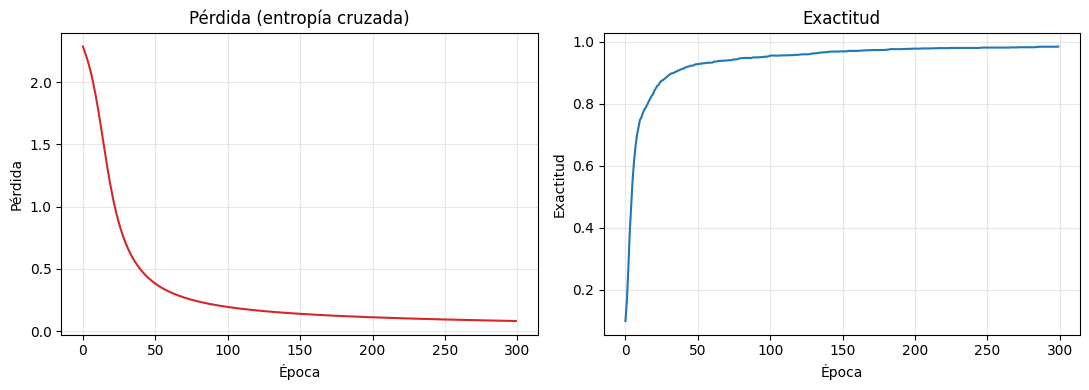

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits

# --- Carga de datos (float32 para usar la mitad de memoria) ---
X, y = load_digits(return_X_y=True)
X = (X / 16).astype(np.float32)
Y = np.eye(10, dtype=np.float32)[y]

# --- Inicialización ---
np.random.seed(0)
lr = 0.5
W1, b1 = (np.random.randn(64, 32) * 0.1).astype(np.float32), np.zeros(32, np.float32)
W2, b2 = (np.random.randn(32, 10) * 0.1).astype(np.float32), np.zeros(10, np.float32)

# --- Entrenamiento (guardamos pérdida y exactitud de cada época) ---
EPOCAS = 300
perdidas, exactitudes = [], []

for epoch in range(EPOCAS):
    # Forward
    h = np.maximum(0, X @ W1 + b1)
    z = h @ W2 + b2
    e = np.exp(z - z.max(1, keepdims=True))  # restar el máximo evita desbordamientos
    p = e / e.sum(1, keepdims=True)

    # Métricas de esta época
    perdidas.append(-np.log(p[np.arange(len(y)), y]).mean())
    exactitudes.append((p.argmax(1) == y).mean())

    # Backward
    d2 = (p - Y) / len(X)
    d1 = (d2 @ W2.T) * (h > 0)

    # Actualización
    W2 -= lr * h.T @ d2; b2 -= lr * d2.sum(0)
    W1 -= lr * X.T @ d1; b1 -= lr * d1.sum(0)

print('Exactitud final:', exactitudes[-1])

# --- Gráfica de la tendencia por época ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.plot(perdidas, color='tab:red')
ax1.set_title('Pérdida (entropía cruzada)')
ax1.set_xlabel('Época')
ax1.set_ylabel('Pérdida')
ax1.grid(alpha=0.3)

ax2.plot(exactitudes, color='tab:blue')
ax2.set_title('Exactitud')
ax2.set_xlabel('Época')
ax2.set_ylabel('Exactitud')
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('tendencia_epocas_digits.png', dpi=150)
plt.show()